# 04 — Comparação, otimização e avaliação
Esta primeira secção compara apenas resultados de desenvolvimento já executados. O teste final permanece reservado.
## Generalização e erros
O F1 médio da referência sempre suspeita é superior ao de todos os classificadores iniciais. A árvore apresenta F1 ligeiramente superior na validação separada, mas não na validação cruzada; uma única divisão não sustenta uma conclusão de superioridade.
Random Forest e SVM apresentam diferenças acentuadas entre F1 de treino e de validação, compatíveis com sobreajustamento neste protocolo. KNN e Gradient Boosting quase não detetam positivos mesmo no treino: isso pode refletir o limiar, o desequilíbrio ou pouco sinal útil, e não demonstra isoladamente uma causa de underfitting.
ROC-AUC próxima de 0,5 e Average Precision próxima da prevalência limitam a evidência de ordenação útil. Não se conclui que qualquer algoritmo seja universalmente inadequado; estes resultados dizem respeito às entradas, parâmetros e dados simulados usados.

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/raw/cybercrime_forensic_dataset.csv').exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.experiencias import tabela_resultados
resultados = json.loads((RAIZ / "resultados/desenvolvimento.json").read_text(encoding="utf-8"))
tabela = tabela_resultados(resultados)
display(tabela.round(4))
tabela.to_csv(RAIZ / "resultados/comparacao_modelos.csv", encoding="utf-8", index=True)

,F1 CV,Desvio F1 CV,F1 treino,F1 validação,Precision,Recall,Accuracy,ROC-AUC,Average Precision,FP,FN
Modelo,,,,,,,,,,,
maioritaria,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.8369,0.5000,0.1631,0,241
sempre_suspeita,0.2850,0.0007,0.2850,0.2804,0.1631,1.0000,0.1631,0.5000,0.1631,1237,0
logistica,0.2368,0.0104,0.2946,0.2448,0.1636,0.4855,0.5115,0.5142,0.1671,598,124
arvore,0.2478,0.0424,0.3020,0.2819,0.1696,0.8340,0.3072,0.5321,0.1743,984,40
random_forest,0.2283,0.0304,0.4582,0.2169,0.1522,0.3776,0.5555,0.4950,0.1560,507,150
knn,0.0027,0.0060,0.0054,0.0000,0.0000,0.0000,0.8363,0.4984,0.1685,1,241
naive_bayes,0.2463,0.0100,0.2922,0.2522,0.1646,0.5394,0.4783,0.5060,0.1766,660,111
svm,0.2402,0.0350,0.5152,0.2101,0.1496,0.3527,0.5677,0.4868,0.1574,483,156
gradient_boosting,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.8363,0.5056,0.1581,1,241


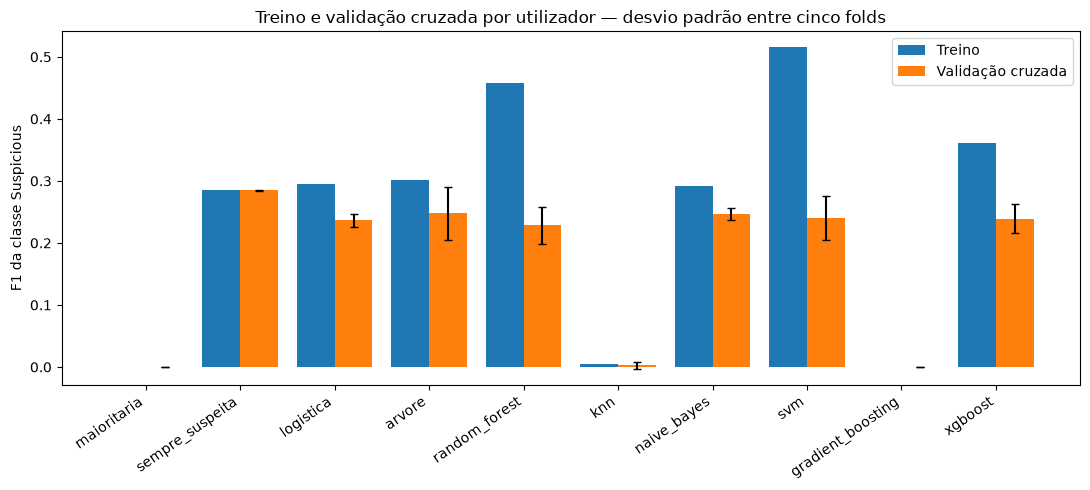

In [2]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(tabela))
ax.bar(x - 0.2, tabela["F1 treino"], 0.4, label="Treino")
ax.bar(x + 0.2, tabela["F1 CV"], 0.4, yerr=tabela["Desvio F1 CV"], capsize=3, label="Validação cruzada")
ax.set_xticks(x, tabela.index, rotation=35, ha="right")
ax.set_ylabel("F1 da classe Suspicious")
ax.set_title("Treino e validação cruzada por utilizador — desvio padrão entre cinco folds")
ax.legend()
fig.tight_layout()
fig.savefig(RAIZ / "resultados/comparacao_modelos.png", dpi=150)
plt.show()

## Protocolo de otimização fixado antes da pesquisa
Serão otimizados os dois classificadores com maior F1 médio na validação cruzada inicial (árvore e Naïve Bayes), acrescentando regressão logística como alternativa simples e regularizada. A pesquisa utilizará apenas os cinco folds de treino, com Pipeline completa.
O limiar será pesquisado conjuntamente com os hiperparâmetros numa grelha limitada de 0, 0,2 e 0,5, dentro da validação cruzada. Incluir zero permite reconhecer explicitamente soluções que equivalem a sinalizar tudo. A validação separada não escolherá o limiar.
A seleção seguirá F1 médio, com Average Precision como critério secundário. Para concretizar a preferência por simplicidade, será usada a heuràstica de **um erro padrão**: entre soluções com F1 pelo menos igual — melhor média menos o seu desvio padrão dividido por raiz de cinco, escolher a mais simples (referência, logística, árvore, Naïve Bayes). Trata-se de uma heuràstica de seleção, não de um intervalo de confiança ou teste de significância: os folds não são amostras independentes.
As referências simples também são candidatas. Se a solução simples permanecer competitiva, não será promovido artificialmente um classificador mais complexo. Os parâmetros, limiar e decisão serão guardados e enviados ao GitHub antes da avaliação no teste.
A comparação de muitas configurações pode introduzir otimismo na validação cruzada; a validação separada e o teste permitirão descrevê-lo, sem reescolher o modelo após ver o teste.

## Pesquisa de hiperparâmetros e limiar
A pesquisa limitada tem 42 configurações e 210 ajustes de folds. Regressão logística varia C e ponderação; árvore varia profundidade e tamanho mínimo das folhas; Naïve Bayes varia priors e suavização. O limiar pertence ao classificador pesquisado, pelo que cada avaliação usa apenas as suas previsões no fold de validação.
A comparação entre as configurações usa F1 e Average Precision; o teste final não entra nesta função. A validação separada é apresentada depois da seleção por validação cruzada, sem servir para ajustar o limiar.

In [3]:
from src.avaliacao_final import carregar_decisao
# A pesquisa foi executada e enviada no commit c6f6558, antes do teste.
# A reprodução usa a decisão assinada; não repete seleção após conhecer o teste.
decisao = carregar_decisao()
display(pd.DataFrame([
    {"Família": c["familia"], "F1 CV": c["f1_cv"], "Desvio F1 CV": c["desvio_f1_cv"],
     "AP CV": c["ap_cv"], "F1 validação": c["validacao"]["f1"],
     "Parâmetros": c["parametros"]}
    for c in decisao["candidatos"]
]).set_index("Família"))
print("Seleção fixada antes do teste:", decisao["selecionado"]["familia"])
print("Melhor candidato de aprendizagem:", decisao["melhor_aprendizagem"]["familia"])
print("Limite da heurística de um erro padrão:", decisao["limite_um_erro_padrao"])
assert decisao["teste_utilizado"] is False
print("Decisão guardada em resultados/decisao_modelo.json.")

,F1 CV,Desvio F1 CV,AP CV,F1 validação,Parâmetros
Família,,,,,
maioritaria,0.000000,0.000000,0.166214,0.000000,{}
sempre_suspeita,0.285048,0.000724,0.166214,0.280396,{}
logistica,0.285104,0.000771,0.164728,0.280396,"{'estimador__modelo__C': 1.0, 'estimador__mode..."
arvore,0.285048,0.000724,0.169663,0.280396,"{'estimador__modelo__max_depth': 5, 'estimador..."
naive_bayes,0.285048,0.000724,0.161515,0.280396,"{'estimador__modelo__priors': None, 'estimador..."


Seleção fixada antes do teste: sempre_suspeita
Melhor candidato de aprendizagem: logistica
Limite da heurística de um erro padrão: 0.2847591480178341
Decisão guardada em resultados/decisao_modelo.json.


## Abertura do teste final
A decisão foi guardada e enviada no commit c6f6558. A sua assinatura canónica é verificada antes da avaliação. O classificador selecionado é a referência sempre suspeita; a logística otimizada é a melhor alternativa aprendida por F1 CV. O F1 quase igual, com previsões constantes na validação, não demonstra uma melhoria útil.
As configurações ficam fixadas. Reajustam-se os modelos no desenvolvimento completo (treino e validação, sem os utilizadores do teste). Avaliam-se apenas as duas referências e a alternativa aprendida previamente escolhida. As métricas de teste não serão utilizadas para mudar a seleção.
Uma reexecução serve para reproduzir os mesmos resultados; o código recusa uma decisão diferente ou uma avaliação que não coincida com o registo final.

In [4]:
from src.avaliacao_final import avaliar_final
resultado_final, detalhes = avaliar_final()
tabela_teste = pd.DataFrame(resultado_final["metricas"]).T
display(tabela_teste[["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision", "tn", "fp", "fn", "tp"]].round(4))
print("Registos de teste:", resultado_final["registos_teste"])
print("Utilizadores de teste:", resultado_final["utilizadores_teste"])
print("Seleção anterior ao teste:", resultado_final["modelo_selecionado"])

,accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp
maioritaria,0.828685,0.0,0.0,0.0,0.5,0.171315,1248,0,258,0
sempre_suspeita,0.171315,0.171315,1.0,0.292517,0.5,0.171315,0,1248,0,258
logistica_otimizada,0.171315,0.171315,1.0,0.292517,0.517793,0.179179,0,1248,0,258


Registos de teste: 1506
Utilizadores de teste: 1007
Seleção anterior ao teste: sempre_suspeita


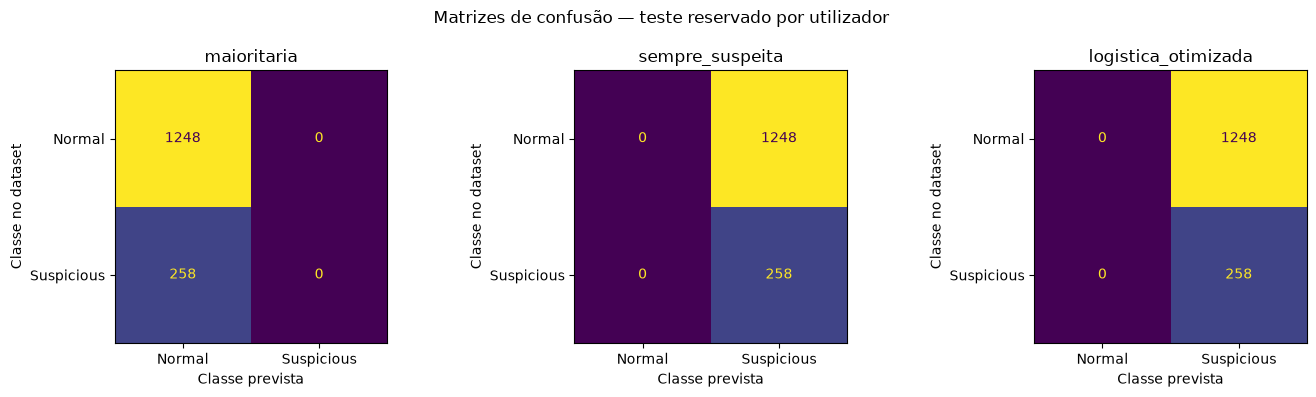

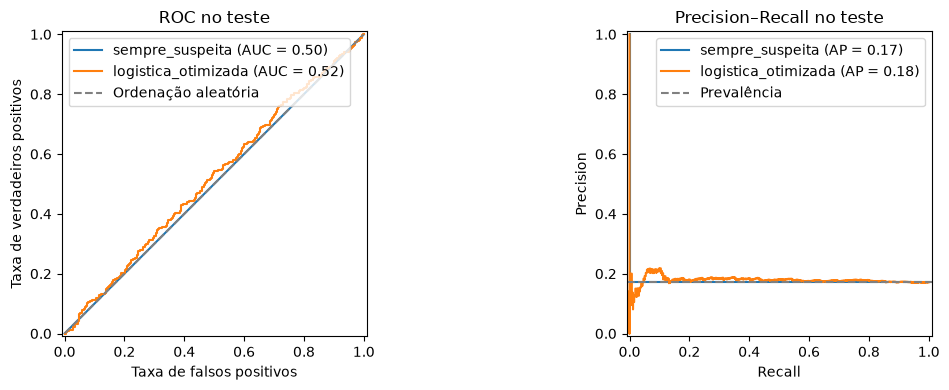

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
fig, eixos = plt.subplots(1, len(detalhes), figsize=(14, 4))
for ax, (nome, dados) in zip(eixos, detalhes.items()):
    ConfusionMatrixDisplay.from_predictions(dados["alvo"], dados["previsoes"], labels=[0, 1],
                                           display_labels=["Normal", "Suspicious"], ax=ax, colorbar=False)
    ax.set_title(nome)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe no dataset")
fig.suptitle("Matrizes de confusão — teste reservado por utilizador")
fig.tight_layout()
fig.savefig(RAIZ / "resultados/matrizes_confusao.png", dpi=150)
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for nome, dados in detalhes.items():
    if nome == "maioritaria":
        continue
    RocCurveDisplay.from_predictions(dados["alvo"], dados["pontuacoes"], name=nome, ax=eixos[0])
    PrecisionRecallDisplay.from_predictions(dados["alvo"], dados["pontuacoes"], name=nome, ax=eixos[1])
eixos[0].plot([0, 1], [0, 1], "--", color="gray", label="Ordenação aleatória")
eixos[0].set(title="ROC no teste", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
eixos[1].axhline(tabela_teste.loc["sempre_suspeita", "precision"], linestyle="--", color="gray", label="Prevalência")
eixos[1].set(title="Precision–Recall no teste", xlabel="Recall", ylabel="Precision")
for ax in eixos:
    ax.legend()
fig.tight_layout()
fig.savefig(RAIZ / "resultados/curvas_teste.png", dpi=150)
plt.show()

## Interpretação e utilidade
A regra sempre suspeita sinaliza todas as atividades. Recall total não significa deteção inteligente: todos os registos normais tornam-se falsos positivos e a carga de alertas é máxima. A referência maioritária apresenta o problema oposto, omitindo todas as atividades suspeitas.
A logística otimizada deve ser interpretada pelas métricas e contagens acima, incluindo a sua capacidade de ordenação. A proximidade às referências e as limitações dos dados não justificam utilização operacional, ainda que o F1 tenha pequenas diferenças.
A conclusão refere-se a rótulos de atividades simuladas de utilizadores não observados, não a incidentes independentes confirmados nem à previsão de períodos futuros. Não é possível garantir eficácia em redes reais. O resultado académico inclui demonstrar estas limitações sem recorrer às colunas que revelam o alvo.